# Lone Island and Glacier Bay: 
### Choose model download areas

#### **Goal:** define two bounding boxes, inspect where they fall on a map, and print the bounds for a future HRRR-AK download.

| Area | Approximate size | Purpose |
| :--- | :--- | :--- |
| Lone Island | 9 × 9 km | Start with a few nearby model grid cells |
| Glacier Bay region | 180 × 180 km | Explore the surrounding region |

> **Reference point, not station location:** both boxes are centered on **58.721963, -136.295474**, from a map pin on Lone Island. The exact station coordinates remain unconfirmed. The regional box is a provisional working extent, not an official park boundary.

### Before you begin

1. Select the **glacierbay** environment in the notebook kernel picker.
2. Run the cells in order, from top to bottom.
3. Inspect the regional map and the close-up before copying any download bounds.

The calculations need no data files. The optional Esri World Topographic Map background uses an internet connection; turn it off below for an offline run. No weather data are downloaded.

## 1. Check the environment and import tools

> **Viewing on GitHub:** figures, tables, and printed results appear only after the notebook has been run and saved with its outputs. In VS Code, select **glacierbay**, choose **Run All**, then **Save** (`Ctrl+S`). Keep outputs when committing the `.ipynb`; GitHub displays saved results without running Python. For the processing notebook, wait until the selected downloads are complete.

In [9]:
# Embed static figures in the saved notebook for GitHub viewing.
%matplotlib inline

# Standard-library tools for paths, the interpreter check, and distance approximations.
from pathlib import Path
import sys
from math import cos, radians

# Check the actual running interpreter, not just the kernel's display name.
if Path(sys.prefix).name != "glacierbay":
    raise RuntimeError(
        "Select the glacierbay environment in the notebook kernel picker, "
        f"then restart and run all cells. Current interpreter: {sys.executable}"
    )
print(f"Python interpreter: {sys.executable}")

# Matplotlib draws the boxes and reference point.
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Contextily supplies optional map tiles; calculations still work without it.
try:
    import contextily as ctx
except ImportError:
    ctx = None
    print("Basemap unavailable: install contextily in glacierbay to enable map tiles.")

Python interpreter: /home/cassie/programs/miniforge3/envs/glacierbay/bin/python


## 2. Set the center and box sizes

Widths and heights are full dimensions, not buffer distances. Change these values to adjust either box. The reference point is kept separate from any future station coordinates.

The calculation uses a local approximation of 111 km per degree of latitude and scales longitude by the cosine of the reference latitude. These are longitude/latitude rectangles, not exact metric squares. The small box is intended to span roughly three nominal 3 km grid spacings in each direction; the actual number of selected grid cells must be checked against the HRRR-AK grid after loading a sample.

**Try later:** change only the widths and heights in the next cell, then rerun the remaining cells. Set `show_basemap = False` to skip online tiles. The other calculations stay the same.

In [10]:
# Map-pin coordinates; do not substitute these for verified station metadata.
reference_point = {"latitude": 58.721963, "longitude": -136.295474}

# Full box dimensions in kilometers (not distance from center to edge).
box_sizes_km = {
    "lone_island": {"width": 9.0, "height": 9.0},
    "glacier_bay_region": {"width": 180.0, "height": 180.0},
}

# Download background map tiles only when this switch is True.
show_basemap = True

## 3. Calculate and report the bounds

A **bounding box** is a rectangle described by its western, eastern, southern, and northern edges. The function below converts our sizes in kilometers into approximate geographic bounds, then applies it to each area.

**Read the output:** `lon_min`/`lon_max` are west/east; `lat_min`/`lat_max` are south/north. `GRIB_AREA` prints the same edges in the order expected by the download script.

In [11]:
def build_bbox(latitude, longitude, width_km, height_km):
    """Return approximate geographic bounds and a wgrib2 area string."""
    if width_km <= 0 or height_km <= 0:
        raise ValueError("Box dimensions must be positive.")
    # Convert half of each box dimension to a latitude/longitude offset.
    half_lat = height_km / (2 * 111.0)
    half_lon = width_km / (2 * 111.0 * cos(radians(latitude)))
    # Subtract/add offsets to get the four geographic edges.
    bounds = {
        "lon_min": longitude - half_lon,
        "lon_max": longitude + half_lon,
        "lat_min": latitude - half_lat,
        "lat_max": latitude + half_lat,
    }
    # Format west:east south:north for wgrib2, retaining negative longitudes.
    bounds["grib_area_string"] = (
        f"{bounds['lon_min']:.6f}:{bounds['lon_max']:.6f} "
        f"{bounds['lat_min']:.6f}:{bounds['lat_max']:.6f}"
    )
    return bounds

# Apply the same calculation to the two chosen sizes.
bounding_boxes = {
    name: build_bbox(
        reference_point["latitude"], reference_point["longitude"],
        size["width"], size["height"],
    )
    for name, size in box_sizes_km.items()
}
bbox_lone_island = bounding_boxes["lone_island"]
bbox_glacier_bay_region = bounding_boxes["glacier_bay_region"]

# Print readable coordinates and a copyable download setting for each box.
for name, bounds in bounding_boxes.items():
    size = box_sizes_km[name]
    print(f"{name} ({size['width']:g} × {size['height']:g} km)")
    print(f"  longitude: {bounds['lon_min']:.6f} to {bounds['lon_max']:.6f}")
    print(f"  latitude:  {bounds['lat_min']:.6f} to {bounds['lat_max']:.6f}")
    print(f"  GRIB_AREA=\"{bounds['grib_area_string']}\"\n")

lone_island (9 × 9 km)
  longitude: -136.373558 to -136.217390
  latitude:  58.681422 to 58.762504
  GRIB_AREA="-136.373558:-136.217390 58.681422:58.762504"

glacier_bay_region (180 × 180 km)
  longitude: -137.857154 to -134.733794
  latitude:  57.911152 to 59.532774
  GRIB_AREA="-137.857154:-134.733794 57.911152:59.532774"



## 4. Locate the boxes on a map

- **Left:** regional overview, with both boxes visible.
- **Right:** close-up of the Lone Island box.
- **Black ×:** the island reference point.

The Esri World Topographic Map background provides coastline and place-name context. We tell Contextily that our axes use longitude/latitude (`EPSG:4326`) so tiles align with the rectangles. This is a working mapping assumption; confirm the original coordinate reference system before station matching.

> **Offline or tile-server problem?** The notebook prints a message and keeps the boxes visible on plain axes. Set `show_basemap = False` to avoid tile requests entirely. Missing map tiles do not affect the numerical bounds.

Map API reference: [Contextily basemap documentation](https://contextily.readthedocs.io/en/latest/reference.html#contextily.add_basemap).

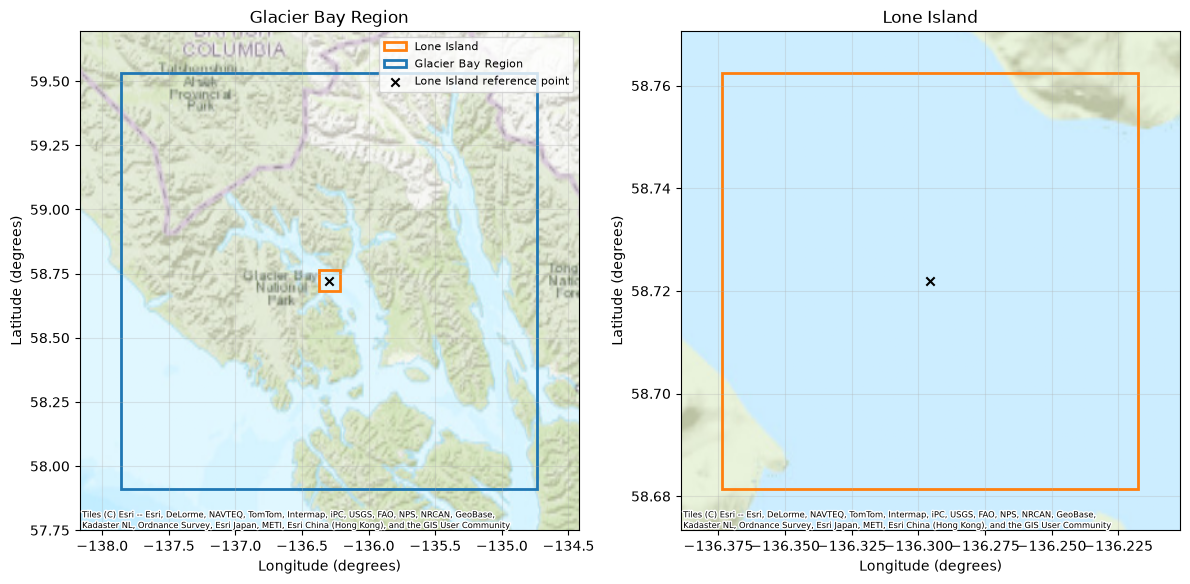

In [12]:
# Create a regional overview and an island close-up side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
colors = {"lone_island": "tab:orange", "glacier_bay_region": "tab:blue"}

for ax, extent_name in zip(axes, ("glacier_bay_region", "lone_island")):
    # Draw both geographic rectangles on each panel.
    for name, bounds in bounding_boxes.items():
        ax.add_patch(Rectangle(
            (bounds["lon_min"], bounds["lat_min"]),
            bounds["lon_max"] - bounds["lon_min"],
            bounds["lat_max"] - bounds["lat_min"],
            fill=False, edgecolor=colors[name], linewidth=2,
            label=name.replace("_", " ").title(),
        ))
    # Mark the shared center independently of any future station location.
    ax.scatter(reference_point["longitude"], reference_point["latitude"],
               color="black", marker="x", zorder=3, label="Lone Island reference point")
    # Set each panel extent with 10% padding before requesting map tiles.
    extent = bounding_boxes[extent_name]
    pad_lon = (extent["lon_max"] - extent["lon_min"]) * 0.1
    pad_lat = (extent["lat_max"] - extent["lat_min"]) * 0.1
    ax.set_xlim(extent["lon_min"] - pad_lon, extent["lon_max"] + pad_lon)
    ax.set_ylim(extent["lat_min"] - pad_lat, extent["lat_max"] + pad_lat)
    # Warp the basemap into lon/lat axes; keep provider attribution visible.
    if show_basemap and ctx is not None:
        try:
            ctx.add_basemap(
                ax, crs="EPSG:4326", source=ctx.providers.Esri.WorldTopoMap,
                zoom=7 if extent_name == "glacier_bay_region" else 11,
                timeout=10, attribution_size=6, zorder=0,
            )
        except Exception as error:
            # A tile failure should not prevent inspecting or using the bounds.
            print(f"Basemap unavailable for {extent_name}: {error}")
            ax.text(0.02, 0.02, "Background map unavailable", transform=ax.transAxes,
                    fontsize=8, bbox={"facecolor": "white", "alpha": 0.8})

    # Correct the approximate visual scale for longitude spacing at this latitude.
    ax.set_aspect(1 / cos(radians(reference_point["latitude"])))
    ax.set_xlabel("Longitude (degrees)")
    ax.set_ylabel("Latitude (degrees)")
    ax.set_title(extent_name.replace("_", " ").title())
    ax.grid(alpha=0.3)

# Finish the figure with a shared key and readable spacing.
axes[0].legend(loc="best", fontsize=8)
fig.tight_layout()
plt.show()

## 5. Review before downloading

- Do the coastline and place names put the boxes where you expect?
- Is the 9 km box suitable for the first small sample? Confirm the actual grid-cell count once model data are loaded.
- Does the regional box cover the area you want? Adjust its dimensions if needed.

Once satisfied, copy the appropriate `GRIB_AREA` value from Step 2 in this workflow into the `download_hrrrak_lone_island.sh` HRRR data download script (see download_hrrrak_readme.txt for notes). 

**This notebook does not edit or run the download script.**

Keep the station location, exact sample dates, and model product choices pending until they are confirmed.